Dataset shape: (10000, 6)

First five rows:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1                 91  
1                                 2                 65  
2                                 2                 45  
3                                 2                 36  
4                                 5                 66  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column           

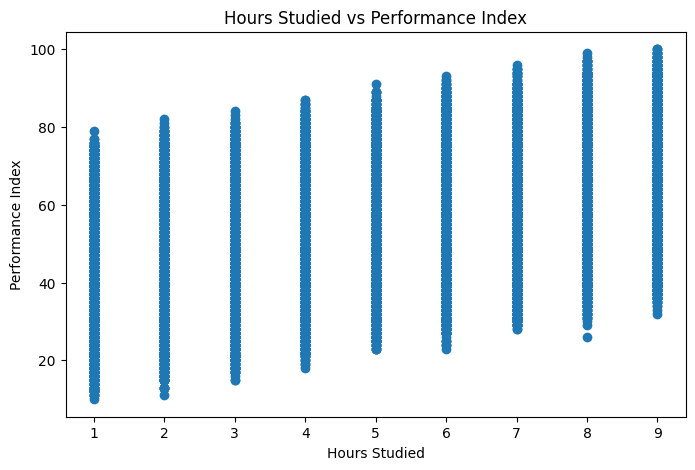

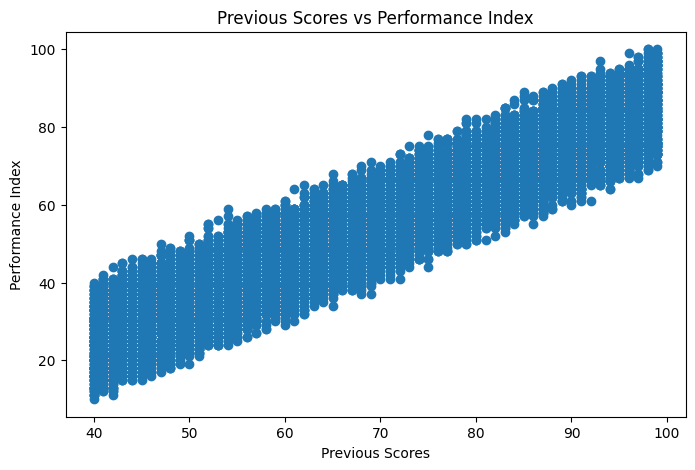

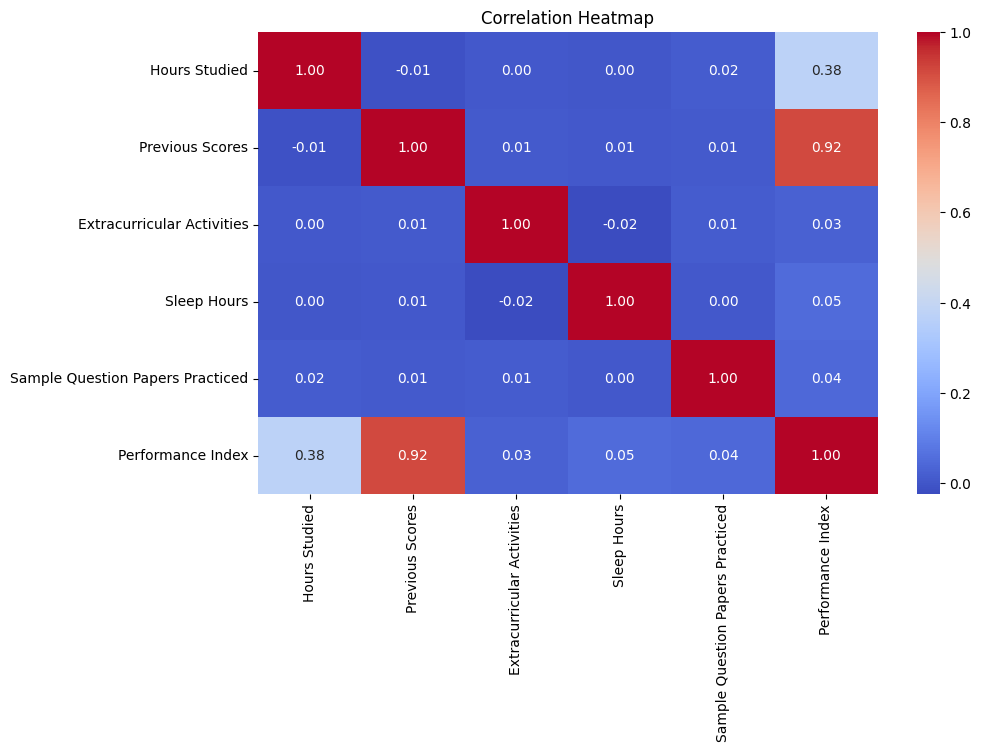


Input features:
   Hours Studied  Previous Scores  Extracurricular Activities  Sleep Hours  \
0              7               99                           1            9   
1              4               82                           0            4   
2              8               51                           1            7   
3              5               52                           1            5   
4              7               75                           0            8   

   Sample Question Papers Practiced  
0                                 1  
1                                 2  
2                                 2  
3                                 2  
4                                 5  

Target variable:
0    91
1    65
2    45
3    36
4    66
Name: Performance Index, dtype: int64

Training samples: 7898
Testing samples: 1975

Linear Regression model trained successfully!

First 10 actual scores:
[47, 76, 62, 23, 76, 83, 60, 51, 38, 58]

First 10 predicted scores:
[46

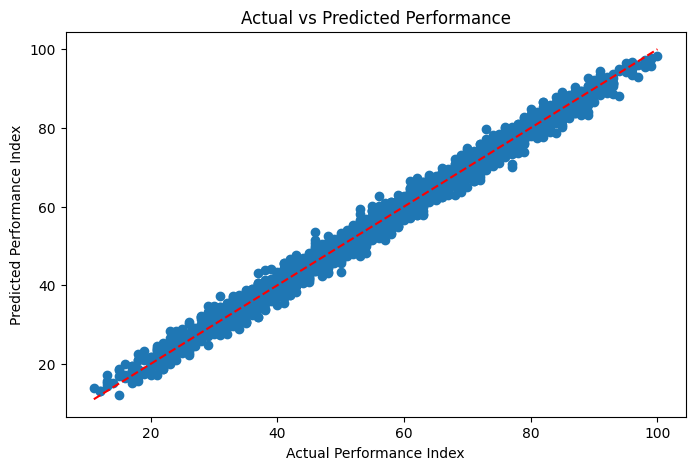


Regression Coefficients:
                            Feature  Coefficient
1                   Previous Scores       17.620
0                     Hours Studied        7.373
3                       Sleep Hours        0.802
4  Sample Question Papers Practiced        0.540
2        Extracurricular Activities        0.287


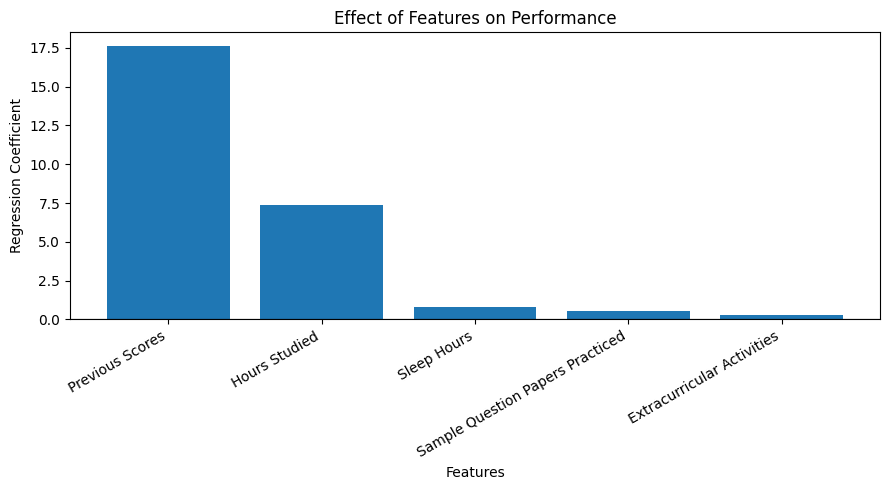

In [1]:

# Q11: Student Performance Prediction Using Regression

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. Load dataset
df = pd.read_csv("/content/Student_Performance - Student_Performance.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

# 2. Check missing values and duplicates
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# 3. Handle missing values and duplicates
df.drop_duplicates(inplace=True)

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# 4. Convert categorical column into numeric
df["Extracurricular Activities"] = df[
    "Extracurricular Activities"
].map({"Yes": 1, "No": 0})

# 5. Explore relationships between features and performance
plt.figure(figsize=(8, 5))
plt.scatter(df["Hours Studied"], df["Performance Index"])
plt.title("Hours Studied vs Performance Index")
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["Previous Scores"], df["Performance Index"])
plt.title("Previous Scores vs Performance Index")
plt.xlabel("Previous Scores")
plt.ylabel("Performance Index")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# 6. Select input features and target
features = [
    "Hours Studied",
    "Previous Scores",
    "Extracurricular Activities",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

X = df[features]
y = df["Performance Index"]

print("\nInput features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

# 7. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 8. Scale input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 9. Train Linear Regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("\nLinear Regression model trained successfully!")

# 10. Predict performance index
y_pred = model.predict(X_test_scaled)

print("\nFirst 10 actual scores:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted scores:")
print(np.round(y_pred[:10], 2))

# 11. Evaluate the model
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("\nModel Evaluation:")
print("R2 Score:", round(r2, 4))
print("RMSE:", round(rmse, 2))
print("MAE:", round(mae, 2))

# 12. Compare actual and predicted values
comparison_df = pd.DataFrame({
    "Actual Performance": y_test.to_numpy(),
    "Predicted Performance": y_pred
})

print("\nActual vs Predicted:")
print(comparison_df.head(10).round(2))

# 13. Plot actual vs predicted values
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)

min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    "r--"
)

plt.title("Actual vs Predicted Performance")
plt.xlabel("Actual Performance Index")
plt.ylabel("Predicted Performance Index")
plt.show()

# 14. Display regression coefficients
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient", ascending=False
)

print("\nRegression Coefficients:")
print(coefficients.round(3))

plt.figure(figsize=(9, 5))
plt.bar(coefficients["Feature"], coefficients["Coefficient"])
plt.title("Effect of Features on Performance")
plt.xlabel("Features")
plt.ylabel("Regression Coefficient")
plt.xticks(rotation=30, ha="right")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
